# LOAN STATUS PREDICTION

### Model to verify if the loan is approved or rejected


In [1]:
import kagglehub
path = kagglehub.dataset_download("architsharma01/loan-approval-prediction-dataset")

100%|██████████| 80.6k/80.6k [00:00<00:00, 27.2MB/s]

Extracting files...


In [2]:
import os
os.listdir(path)

['loan_approval_dataset.csv']

In [3]:
import pandas as pd
df=pd.read_csv(os.path.join(path,'loan_approval_dataset.csv'))

In [4]:
df.shape

(4269, 13)

In [5]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [7]:
df.isnull().sum()

,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


### There are no null values in the dataset

In [8]:
df.duplicated().sum()

np.int64(0)

### There are no duplicates in dataset

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [10]:
df[' education'].dtype

dtype('O')

In [11]:
categorical=[i for i in df.columns if df[i].dtypes=='O']
numerical=[i for i in df.columns if i not in categorical]
print("Categorical Features are : ",categorical)
print("Numerical Features are : ",numerical)

Categorical Features are :  [' education', ' self_employed', ' loan_status']
Numerical Features are :  ['loan_id', ' no_of_dependents', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value']


In [12]:
for col in categorical:
  print(f"For{col}, unique values are : {df[col].unique()}")

For education, unique values are : [' Graduate' ' Not Graduate']
For self_employed, unique values are : [' No' ' Yes']
For loan_status, unique values are : [' Approved' ' Rejected']


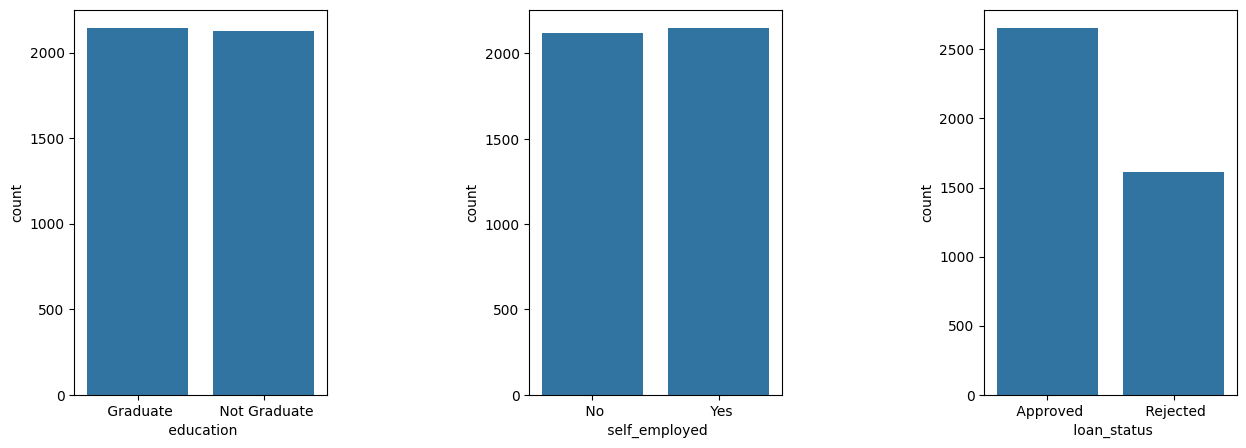

In [13]:
fig,axes=plt.subplots(1,3,figsize=(15,5))
sns.countplot(df,x=' education',ax=axes[0])
sns.countplot(df,x=' self_employed',ax=axes[1])
sns.countplot(df,x=' loan_status',ax=axes[2])
plt.subplots_adjust(wspace=0.8)
plt.show()

## Graduate and Non Graduate people are almost same or comparable.
## Number of people who are self employed and not are also comparable.
## Data is not uniformly distributed as per Approved and Rejected loan status.
## Rejections are less the approvals.

### There are no inappropriate values in the dataset.

# Numerical colums Univariate Analysis:

In [14]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [15]:
df['loan_id'].is_unique

True

In [16]:
df[' no_of_dependents'].unique()

array([2, 0, 3, 5, 4, 1])

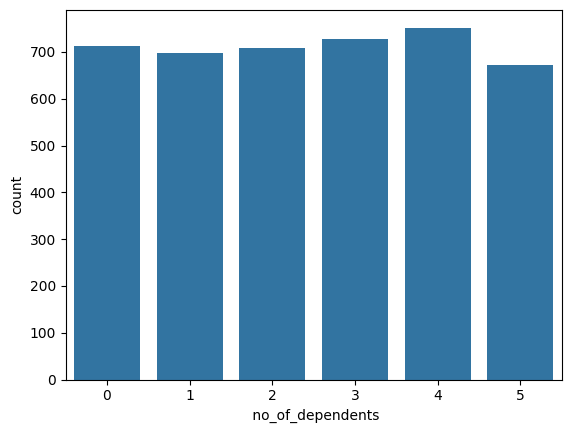

In [17]:
sns.countplot(df,x=' no_of_dependents')
plt.show()

# No. of dependents will also come as categorical column with 6 categories

In [18]:
categorical.append(' no_of_dependents')
numerical.remove(' no_of_dependents')

In [19]:
print(categorical)
print(numerical)

[' education', ' self_employed', ' loan_status', ' no_of_dependents']
['loan_id', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value']


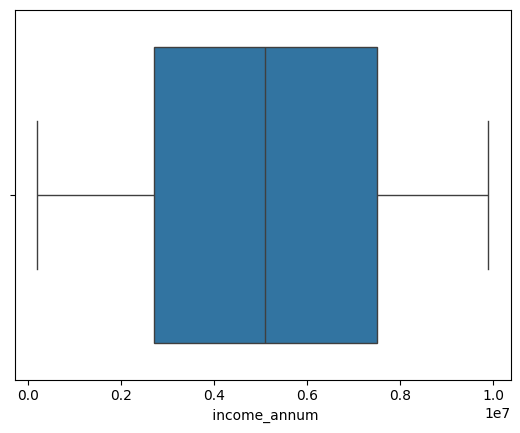

In [20]:
sns.boxplot(df,x=' income_annum')
plt.show()

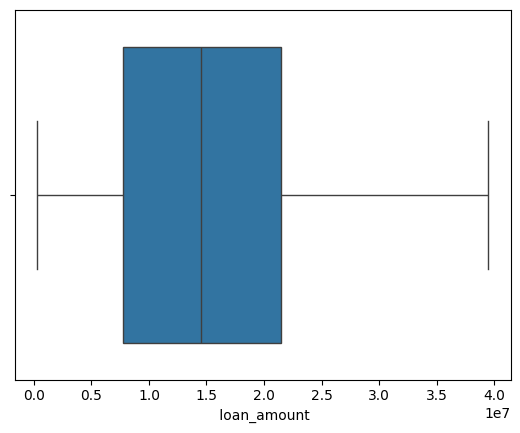

In [21]:
sns.boxplot(df,x=' loan_amount')
plt.show()

## There are no outliers detected for the columns income and loan amount

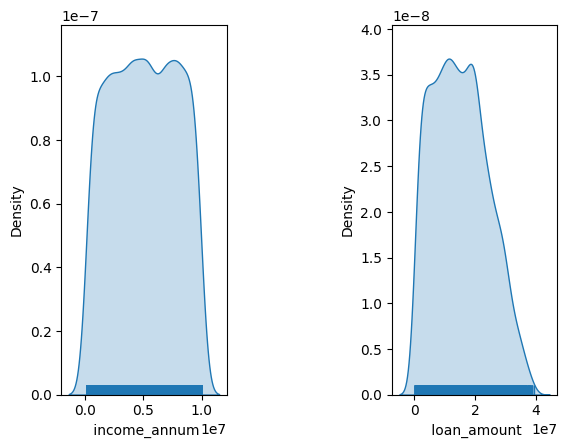

In [22]:
fig,axes=plt.subplots(1,2)
sns.kdeplot(df,x=' income_annum',ax=axes[0],fill=True)
sns.rugplot(df,x=' income_annum',ax=axes[0])
sns.kdeplot(df,x=' loan_amount',ax=axes[1],fill=True)
sns.rugplot(df,x=' loan_amount',ax=axes[1])
plt.subplots_adjust(wspace=1)
plt.show()

In [23]:
df[' loan_term'].unique()

array([12,  8, 20, 10,  4,  2, 18, 16, 14,  6])

# Since this column also have only few categories so it can also be considered as categorical

In [24]:
categorical.append(' loan_term')
numerical.remove(' loan_term')

In [25]:
print(categorical)
print(numerical)

[' education', ' self_employed', ' loan_status', ' no_of_dependents', ' loan_term']
['loan_id', ' income_annum', ' loan_amount', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value']


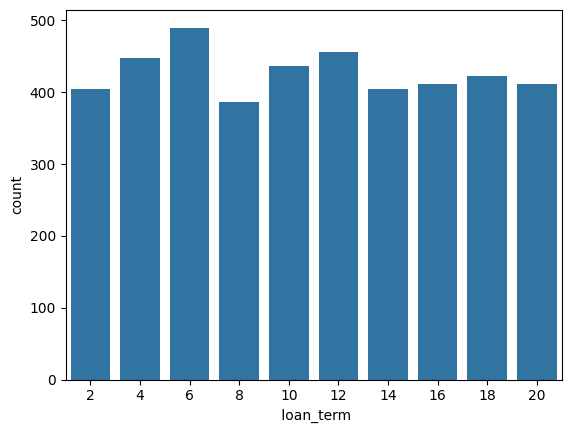

In [26]:
sns.countplot(df,x=' loan_term')
plt.show()

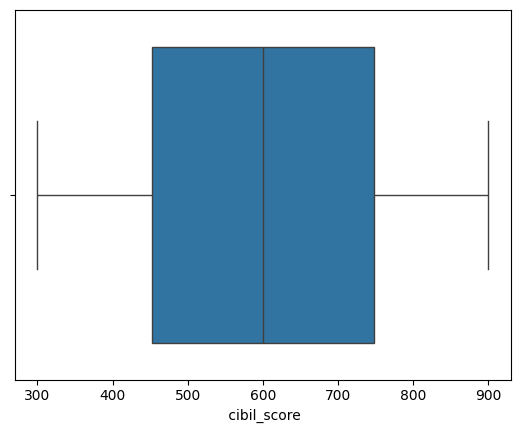

In [27]:
sns.boxplot(df,x=' cibil_score')
plt.show()

### The column cibil_score is too free from outliers
### Since residential_assets_value, commercial_assets_value, luxury_assets_value, bank_asset_value all are related to assets of the applicant we can simply come up with their sum and then analyse.

In [28]:
df['assets_value']=df[' residential_assets_value']+df[' commercial_assets_value']+df[' luxury_assets_value']+df[' bank_asset_value']

In [29]:
df.drop(columns=[' residential_assets_value',' commercial_assets_value',' luxury_assets_value',' bank_asset_value'],inplace=True)

In [30]:
numerical.append('assets_value')
numerical.remove(' residential_assets_value')
numerical.remove(' commercial_assets_value')
numerical.remove(' luxury_assets_value')
numerical.remove(' bank_asset_value')

In [31]:
print(numerical)

['loan_id', ' income_annum', ' loan_amount', ' cibil_score', 'assets_value']


In [32]:
df.sample()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,assets_value
859,860,0,Not Graduate,Yes,600000,1800000,12,511,Rejected,3100000


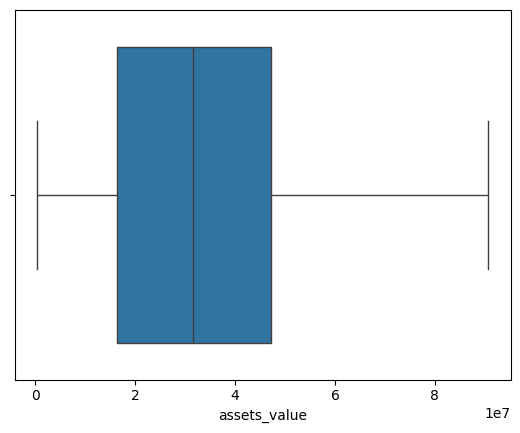

In [33]:
sns.boxplot(df,x='assets_value')
plt.show()

# The dataset is outlier free

## Exploratory Data Analysis

## Categorical Vs Numerical

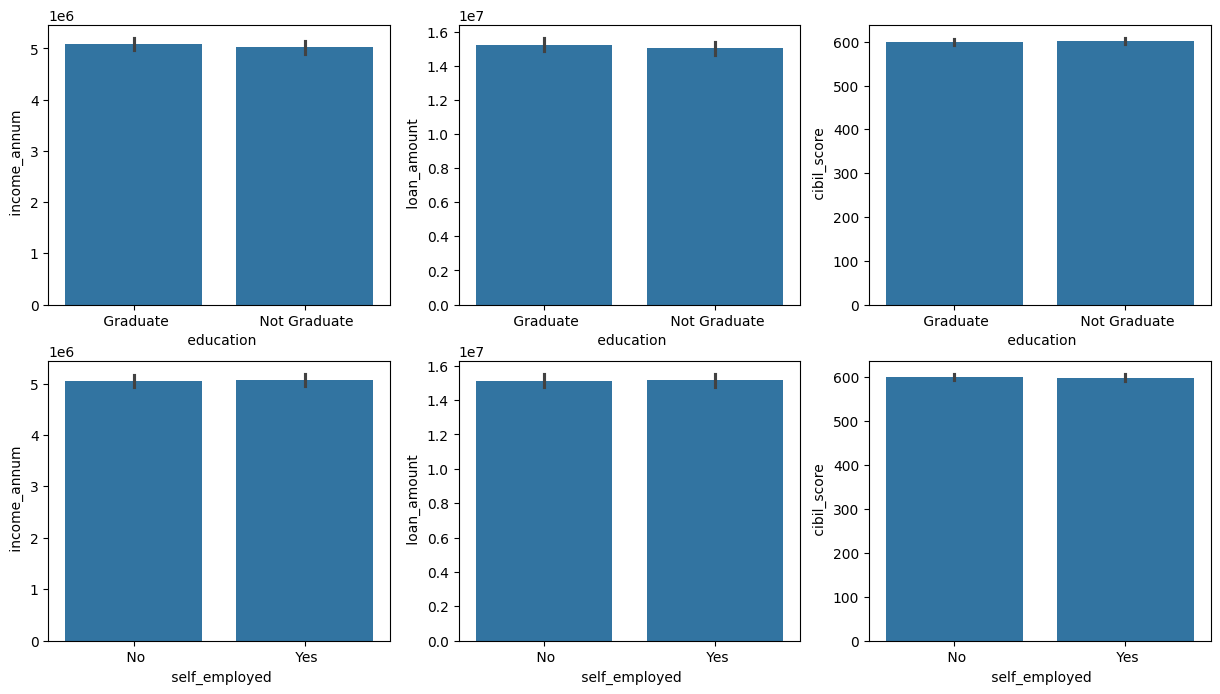

In [34]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
sns.barplot(df,x=' education',y=' income_annum',ax=axes[0,0])
sns.barplot(df,x=' education',y=' loan_amount',ax=axes[0,1])
sns.barplot(df,x=' education',y=' cibil_score',ax=axes[0,2])
sns.barplot(df,x=' self_employed',y=' income_annum',ax=axes[1,0])
sns.barplot(df,x=' self_employed',y=' loan_amount',ax=axes[1,1])
sns.barplot(df,x=' self_employed',y=' cibil_score',ax=axes[1,2])
plt.show()

### Annual income earned,loan amount applied and cibil score are coming comparable among graduates and non graduates
### Annual income earned,loan amount applied and cibil score are coming comparable among self employed and non self employed

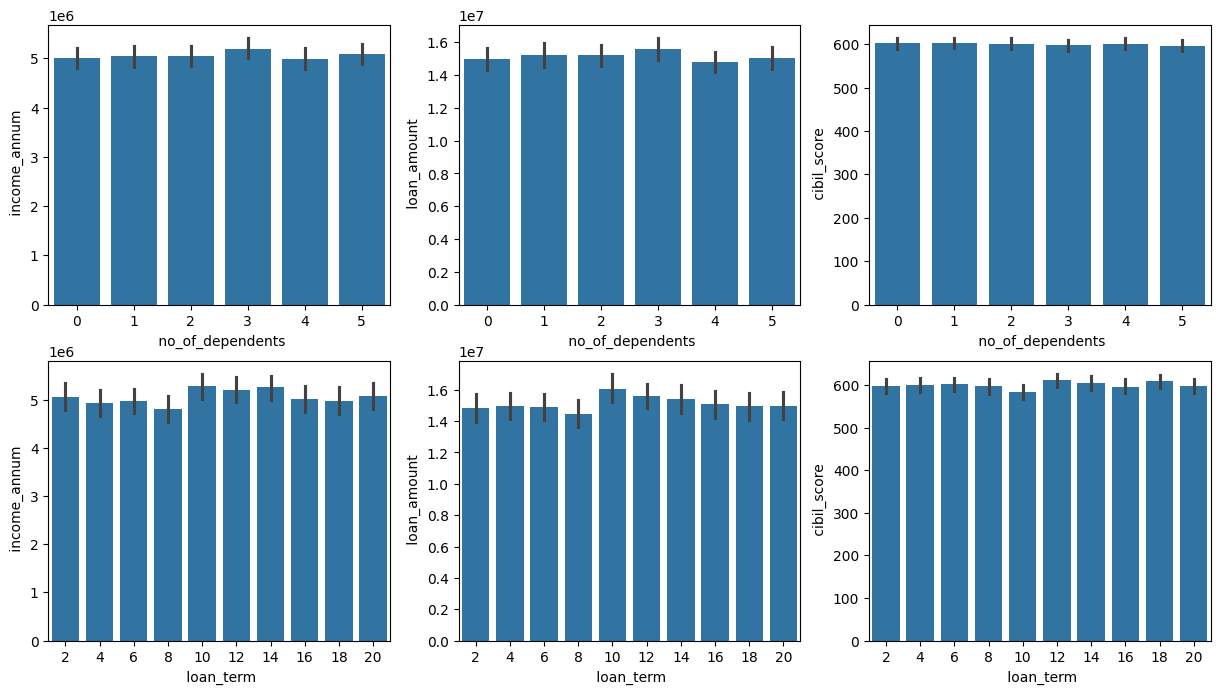

In [35]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
sns.barplot(df,x=' no_of_dependents',y=' income_annum',ax=axes[0,0])
sns.barplot(df,x=' no_of_dependents',y=' loan_amount',ax=axes[0,1])
sns.barplot(df,x=' no_of_dependents',y=' cibil_score',ax=axes[0,2])
sns.barplot(df,x=' loan_term',y=' income_annum',ax=axes[1,0])
sns.barplot(df,x=' loan_term',y=' loan_amount',ax=axes[1,1])
sns.barplot(df,x=' loan_term',y=' cibil_score',ax=axes[1,2])
plt.show()

## People with 3 dependents are earning quite a more and also asking more loan followed by 5 and then comparable among rest.
## Cibil Score is coming quite same for all people with any number of followers.
## People asking loan for 10-12 months are earning more and asking for more loan while others are quite comparable.
## People asking loan for 10 months have least cibil score.

# NUMERICAL VS NUMERICAL

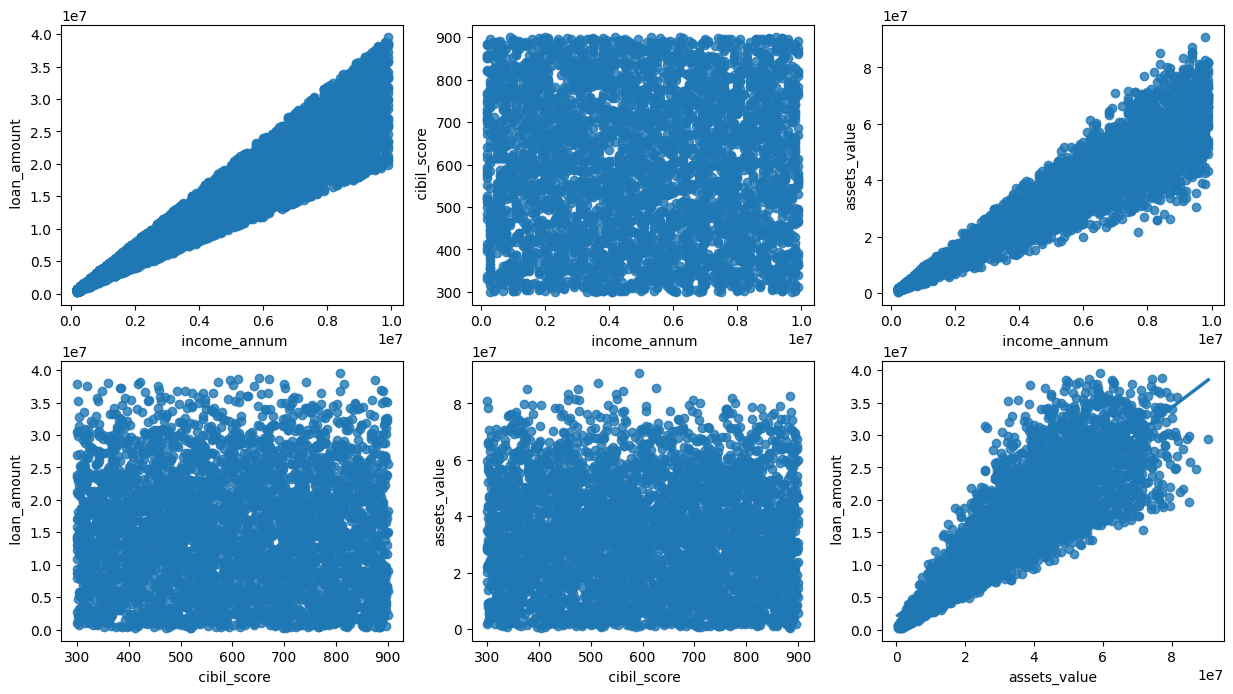

In [36]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
sns.regplot(df,x=' income_annum',y=' loan_amount',ax=axes[0,0])
sns.regplot(df,x=' income_annum',y=' cibil_score',ax=axes[0,1])
sns.regplot(df,x=' income_annum',y='assets_value',ax=axes[0,2])
sns.regplot(df,x=' cibil_score',y=' loan_amount',ax=axes[1,0])
sns.regplot(df,y='assets_value',x=' cibil_score',ax=axes[1,1])
sns.regplot(df,x='assets_value',y=' loan_amount',ax=axes[1,2])
plt.show()

## We can visualise with increase in income overall assets value is also increasing linearly.
## As assets are increasing, individual demand for loan is also increasing almost linearly.
## Individuals with low income has both high or low cibil score and also with high income have both high or low cibil score.
## Wrt Cibil score, assets may or may not increase based on individual.

In [37]:
print(categorical)
print(numerical)

[' education', ' self_employed', ' loan_status', ' no_of_dependents', ' loan_term']
['loan_id', ' income_annum', ' loan_amount', ' cibil_score', 'assets_value']


# CATEGORICAL VS CATEGORICAL

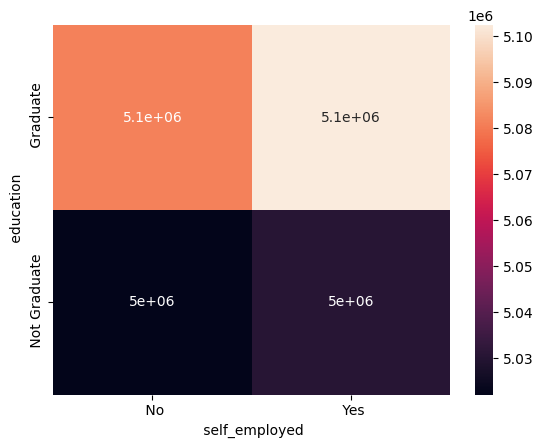

In [38]:
table1=pd.pivot_table(df,index=' education',columns=' self_employed',values=' income_annum',aggfunc='mean')
sns.heatmap(table1,annot=True)
plt.show()

## Overall Graduates are earning more as compared to non graduates.
## self-employed graduates are earning more as compared to non-self employed graduates
## Also self employed earn more as compared to non self employed

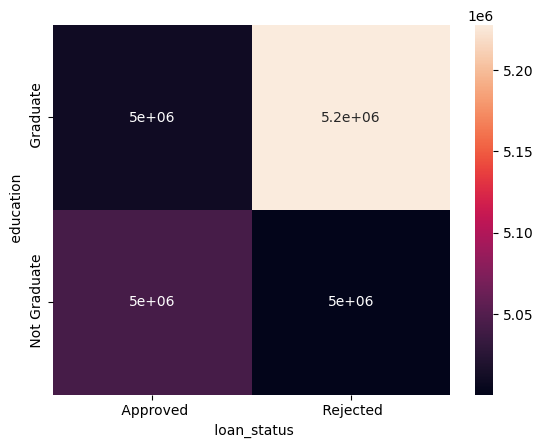

In [39]:
table1=pd.pivot_table(df,index=' education',columns=' loan_status',values=' income_annum',aggfunc='mean')
sns.heatmap(table1,annot=True)
plt.show()

## Graduated People with more rejections are earning most followed by by non graduated people with more approvals.

In [40]:
df.drop(columns=['loan_id'],inplace=True)


In [41]:
x=df.drop(columns=[' loan_status'])
y=df[' loan_status']

In [42]:
y

,loan_status
0,Approved
1,Rejected
2,Rejected
3,Rejected
4,Rejected
...,...
4264,Rejected
4265,Approved
4266,Rejected
4267,Approved


In [43]:
df.sample()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,assets_value
4187,3,Not Graduate,No,4100000,14100000,8,367,Rejected,15900000


In [44]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder
from sklearn.compose import ColumnTransformer
ct=ColumnTransformer(transformers=[
    ('ohe',OneHotEncoder(drop='first'),[' self_employed']),
    ('oe',OrdinalEncoder(categories=[[' Not Graduate',' Graduate']]),[' education'])
],remainder='passthrough')
data=ct.fit_transform(x)

In [45]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
data=scaler.fit_transform(data)

In [46]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y=le.fit_transform(y)

In [47]:
y

array([0, 1, 1, ..., 1, 0, 0])

# 0 -> Approved
# 1 -> Rejected

In [48]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(data,y,test_size=0.2,random_state=42)

In [49]:
x_train.shape,y_train.shape

((3415, 8), (3415,))

In [50]:
x_train

array([[-1.00728821, -1.00446064,  1.47506715, ..., -0.85844427,
        -0.18523295,  0.60249499],
       [ 0.99276452, -1.00446064, -1.4735476 , ...,  0.19261651,
         0.6383842 ,  2.43286266],
       [-1.00728821,  0.99555917, -0.88382465, ..., -0.50809068,
         0.47598082, -1.31503305],
       ...,
       [ 0.99276452, -1.00446064,  0.8853442 , ...,  0.8933237 ,
        -0.87544732,  1.17672798],
       [ 0.99276452, -1.00446064, -0.2941017 , ...,  0.19261651,
        -0.34183621,  0.09491404],
       [-1.00728821,  0.99555917,  0.8853442 , ..., -0.85844427,
         1.37499953,  0.66914703]])

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

In [52]:
models={
    'Logistic Regressor':LogisticRegression(),
    'Support Vector Classifier':SVC(),
    'KNN':KNeighborsClassifier(),
    'Naive Bayes':BernoulliNB()
}
accuracy={}
for i in range(len(list(models))):
  model=list(models.values())[i]
  model.fit(x_train,y_train)
  y_train_pred=model.predict(x_train)
  y_test_pred=model.predict(x_test)
  train_accuracy=accuracy_score(y_train,y_train_pred)
  test_accuracy=accuracy_score(y_test,y_test_pred)
  accuracy[list(models)[i]]=train_accuracy
  accuracy[list(models)[i]+'_test']=test_accuracy
  print(f'For {list(models)[i]} :')
  print('Training Model report :')
  print(confusion_matrix(y_train,y_train_pred))
  print('Testing Model report :')
  print(confusion_matrix(y_test,y_test_pred),'\n')

For Logistic Regressor :
Training Model report :
[[1980  140]
 [ 137 1158]]
Testing Model report :
[[499  37]
 [ 44 274]] 

For Support Vector Classifier :
Training Model report :
[[2035   85]
 [  56 1239]]
Testing Model report :
[[505  31]
 [ 26 292]] 

For KNN :
Training Model report :
[[2042   78]
 [  65 1230]]
Testing Model report :
[[489  47]
 [ 25 293]] 

For Naive Bayes :
Training Model report :
[[1713  407]
 [  10 1285]]
Testing Model report :
[[412 124]
 [  1 317]] 



In [53]:
pd.DataFrame(list(accuracy.values()),index=list(accuracy))

,0
Logistic Regressor,0.918887
Logistic Regressor_test,0.905152
Support Vector Classifier,0.958712
Support Vector Classifier_test,0.933255
KNN,0.958126
KNN_test,0.915691
Naive Bayes,0.877892
Naive Bayes_test,0.853630


## SVC is performing best among all these models

In [54]:
model=SVC()
model.fit(x_train,y_train)
pred=model.predict(x_test)

In [55]:
accuracy_score(y_test,pred)

0.9332552693208431

In [56]:
from sklearn.pipeline import Pipeline
import numpy as np
input=(0,' Graduate',' Yes',5400000,12900000,16,355,39900000)
prediction_pipeline=Pipeline(steps=[
    ('ct',ct),
    ('scaler',StandardScaler()),
    ('model',SVC())
])
prediction_pipeline.fit(x,y)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ohe',
                                                  OneHotEncoder(drop='first'),
                                                  [' self_employed']),
                                                 ('oe',
                                                  OrdinalEncoder(categories=[[' '
                                                                              'Not '
                                                                              'Graduate',
                                                                              ' '
                                                                              'Graduate']]),
                                                  [' education'])])),
                ('scaler', StandardScaler()), ('model', SVC())])

In [57]:
df.sample()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,loan_status,assets_value
1204,5,Graduate,Yes,1800000,5300000,12,461,Rejected,11500000


In [58]:
user_input = {
    ' no_of_dependents': [1],
    ' education': [' Graduate'],
    ' self_employed': [' Yes'],
    ' income_annum': [12200000],
    ' loan_amount': [46000000],
    ' loan_term': [20],
    ' cibil_score': [600],
    'assets_value': [18400000]
}
datapoint=pd.DataFrame(user_input)

In [59]:
prediction_pipeline.predict(datapoint)

array([0])

In [60]:
import pickle
with open('pipeline.pkl','wb') as f:
  pickle.dump(prediction_pipeline,f)